In [1]:
import xgboost
import sklearn
import pandas
import matplotlib

print("XGBoost version:", xgboost.__version__)
print("All libraries imported successfully!")

ModuleNotFoundError: No module named 'xgboost'

In [2]:
import sys

print(sys.executable)

C:\Users\Admin\AppData\Local\Programs\Python\Python313\python.exe


In [3]:
%pip install xgboost scikit-learn pandas matplotlib

  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: C:\Users\Admin\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [1]:
import xgboost
import sklearn
import pandas
import matplotlib

print("XGBoost version:", xgboost.__version__)
print("All libraries imported successfully!")

XGBoost version: 3.4.1
All libraries imported successfully!


In [2]:
import sys

print(sys.executable)

C:\Users\Admin\AppData\Local\Programs\Python\Python313\python.exe


In [1]:
import sys
print(sys.executable)

import xgboost
print("XGBoost version:", xgboost.__version__)
print("Successfully imported!")

C:\Users\Admin\Desktop\PYTHONTRAIN\.venv\Scripts\python.exe
XGBoost version: 3.4.1
Successfully imported!


In [1]:
import sys
print(sys.executable)

import xgboost
print("XGBoost version:", xgboost.__version__)
print("Successfully imported!")

C:\Users\Admin\Desktop\PYTHONTRAIN\.venv\Scripts\python.exe
XGBoost version: 3.4.1
Successfully imported!


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

from xgboost import XGBClassifier

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:

data = load_breast_cancer()


df = pd.DataFrame(data.data, columns=data.feature_names)

df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [4]:
print("Dataset shape:", df.shape)
print("Target classes:", data.target_names)

Dataset shape: (569, 30)
Target classes: ['malignant' 'benign']


In [5]:

X = data.data
y = data.target


X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.20,
    random_state=42,
    stratify=y_train_full
)

print("Training samples:", X_train.shape[0])
print("Validation samples:", X_val.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 364
Validation samples: 91
Testing samples: 114


In [6]:
learning_rates = [0.3, 0.1, 0.03]
tree_counts = [100, 300, 1000]

models = {}
results = []

for lr, trees in zip(learning_rates, tree_counts):

    print(f"\nTraining with learning_rate={lr}")

    model = XGBClassifier(
        n_estimators=trees,
        learning_rate=lr,
        max_depth=3,
        random_state=42,
        eval_metric="logloss",
        early_stopping_rounds=20
    )

    model.fit(
        X_train,
        y_train,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    
    y_pred = model.predict(X_test)

    
    accuracy = accuracy_score(y_test, y_pred)

  
    models[lr] = model

    results.append({
        "learning_rate": lr,
        "best_iteration": model.best_iteration,
        "test_accuracy": accuracy
    })

    print("Best iteration:", model.best_iteration)
    print("Test accuracy:", accuracy)


Training with learning_rate=0.3
Best iteration: 32
Test accuracy: 0.9385964912280702

Training with learning_rate=0.1
Best iteration: 104
Test accuracy: 0.9473684210526315

Training with learning_rate=0.03
Best iteration: 146
Test accuracy: 0.9385964912280702


In [7]:
results_df = pd.DataFrame(results)

print("XGBoost Learning Rate Comparison")
display(results_df)

XGBoost Learning Rate Comparison


,learning_rate,best_iteration,test_accuracy
0,0.30,32,0.938596
1,0.10,104,0.947368
2,0.03,146,0.938596


In [8]:

best_model = models[0.1]


importance = pd.DataFrame({
    "Feature": data.feature_names,
    "Importance": best_model.feature_importances_
})


importance = importance.sort_values(
    by="Importance",
    ascending=False
)

display(importance.head(10))

,Feature,Importance
22,worst perimeter,0.277640
27,worst concave points,0.202978
20,worst radius,0.065055
3,mean area,0.056792
1,mean texture,0.045931
23,worst area,0.043567
7,mean concave points,0.040622
25,worst compactness,0.039757
26,worst concavity,0.035459
24,worst smoothness,0.034246


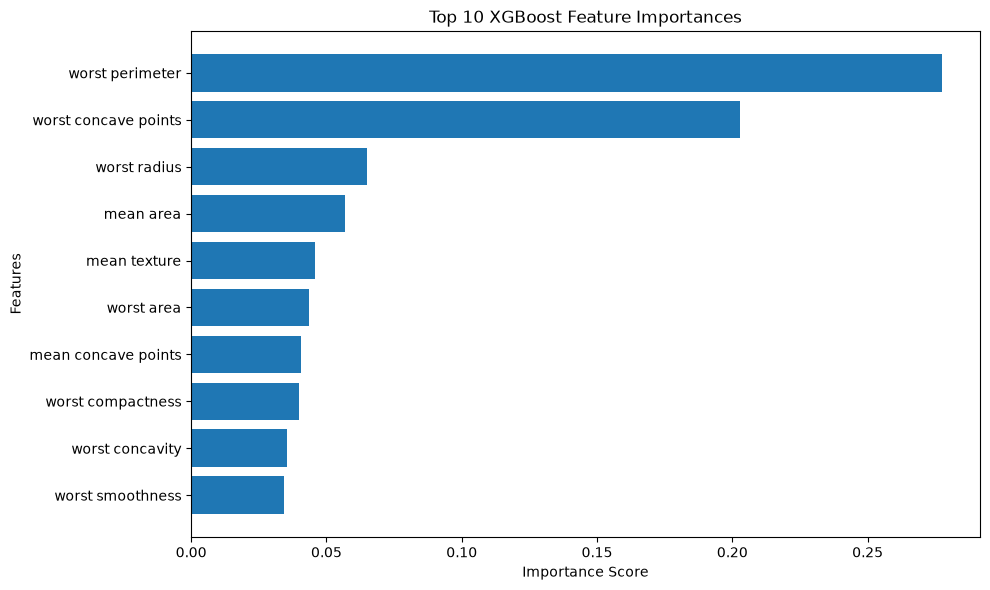

In [9]:

top_features = importance.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Top 10 XGBoost Feature Importances")

plt.tight_layout()
plt.show()

In [10]:
results_df = pd.DataFrame(results)

results_df.columns = [
    "learning_rate",
    "best iteration",
    "test accuracy"
]

display(results_df)

,learning_rate,best iteration,test accuracy
0,0.30,32,0.938596
1,0.10,104,0.947368
2,0.03,146,0.938596


In [11]:
final_table = pd.DataFrame(results)

final_table = final_table.rename(columns={
    "learning_rate": "learning_rate",
    "best_iteration": "best iteration",
    "test_accuracy": "test accuracy"
})

final_table["test accuracy"] = (
    final_table["test accuracy"].round(4)
)

display(final_table.style.hide(axis="index"))

AttributeError: The '.style' accessor requires jinja2

In [12]:
final_table = pd.DataFrame(results)

final_table = final_table.rename(columns={
    "learning_rate": "learning_rate",
    "best_iteration": "best iteration",
    "test_accuracy": "test accuracy"
})

final_table["test accuracy"] = final_table["test accuracy"].round(4)

print(final_table.to_string(index=False))

 learning_rate  best iteration  test accuracy
          0.30              32         0.9386
          0.10             104         0.9474
          0.03             146         0.9386
